# 01 – Exploratory Data Analysis

First look at the data (CRISP-DM phase 2, Data Understanding).

Before running: build the database with `python src/load_db.py` from the repo root.

Sections:
1. Overview of the 22 tables
2. How the NHL changed over time (eras)
3. Task (a): how predictable is a team's points% from last season?
4. Task (b): how often do teams change coach?

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

con = sqlite3.connect("../data/hockey.db")
q = lambda sql: pd.read_sql(sql, con)
sql_file = lambda name: q(open(f"../sql/{name}").read())

sns.set_theme(style="whitegrid")

## 1. Overview of the tables

For each table: number of rows and columns, years covered, and % of missing cells.

In [2]:
tables = q("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")["name"]
rows = []
for t in tables:
    df = q(f"SELECT * FROM {t}")
    years = (df["year"].min(), df["year"].max()) if "year" in df else (None, None)
    rows.append({
        "table": t,
        "rows": len(df),
        "cols": df.shape[1],
        "first_year": years[0],
        "last_year": years[1],
        "pct_missing": round(100 * df.isna().mean().mean(), 1),
    })
overview = pd.DataFrame(rows).sort_values("rows", ascending=False)
overview

,table,rows,cols,first_year,last_year,pct_missing
10,Scoring,43848,31,1909.0,2009.0,34.1
16,TeamVsTeam,23862,8,1909.0,2009.0,10.3
9,Master,7469,31,NaN,NaN,38.8
5,Goalies,4096,23,1909.0,2009.0,30.8
2,AwardsPlayers,2021,6,1917.0,2009.0,22.5
3,Coaches,1741,14,1909.0,2009.0,21.0
12,ScoringShootout,1487,7,2005.0,2009.0,0.0
15,TeamSplits,1459,43,1909.0,2009.0,33.2
17,Teams,1459,27,1909.0,2009.0,21.7
19,TeamsPost,895,17,1913.0,2009.0,15.3


Seasons in the data, and teams per NHL season (2004 should be missing: lockout).

NHL seasons without data: [2004]


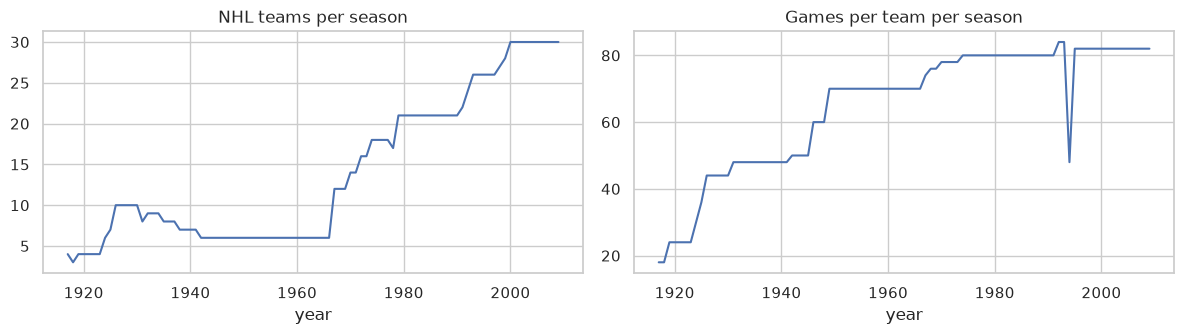

In [3]:
per_season = q("""
SELECT year, COUNT(*) AS teams, AVG(G) AS games
FROM Teams WHERE lgID = 'NHL'
GROUP BY year ORDER BY year
""")
missing_years = sorted(set(range(per_season.year.min(), per_season.year.max() + 1)) - set(per_season.year))
print("NHL seasons without data:", missing_years)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
per_season.plot(x="year", y="teams", ax=ax[0], legend=False, title="NHL teams per season")
per_season.plot(x="year", y="games", ax=ax[1], legend=False, title="Games per team per season")
plt.tight_layout()

## 2. How the game changed (eras)

Goals per game and % of tied games per NHL season. Rule changes make old seasons less comparable to recent ones, which matters when deciding which years to train on.

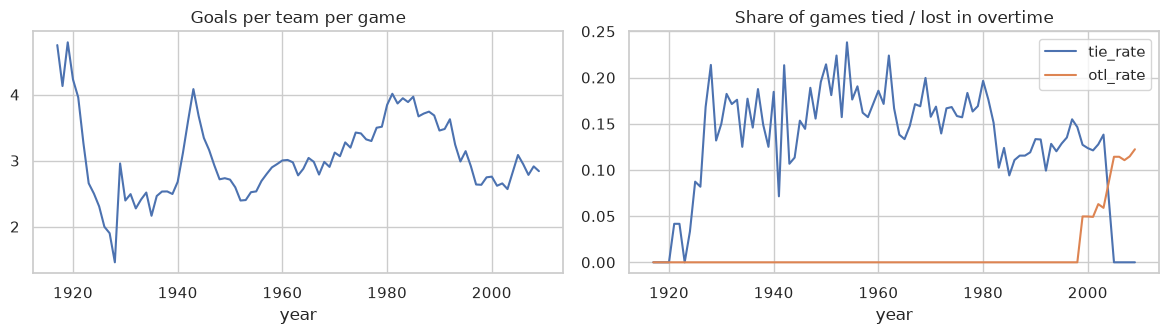

In [4]:
eras = q("""
SELECT year,
       SUM(GF) * 1.0 / SUM(G)              AS goals_per_team_game,
       SUM(COALESCE(T, 0)) * 1.0 / SUM(G)  AS tie_rate,
       SUM(COALESCE(OTL, 0)) * 1.0 / SUM(G) AS otl_rate
FROM Teams WHERE lgID = 'NHL'
GROUP BY year ORDER BY year
""")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
eras.plot(x="year", y="goals_per_team_game", ax=ax[0], legend=False, title="Goals per team per game")
eras.plot(x="year", y=["tie_rate", "otl_rate"], ax=ax[1], title="Share of games tied / lost in overtime")
plt.tight_layout()

## 3. Task (a): is last season a good predictor?

Query in [`sql/pts_pct_lag.sql`](../sql/pts_pct_lag.sql): points% = `Pts / (2·G)` for each team-season, plus the same franchise's value the season before (`LAG() OVER (PARTITION BY franchID ORDER BY year)`).

In [5]:
lag = sql_file("pts_pct_lag.sql")
# keep consecutive seasons only (2005 follows 2003 because 2004 is missing)
lag = lag[(lag.year - lag.prev_year == 1) | ((lag.year == 2005) & (lag.prev_year == 2003))]
print(len(lag), "team-seasons with a previous season")
lag[["pts_pct", "pts_pct_prev", "gd_per_game_prev"]].corr()

1228 team-seasons with a previous season


,pts_pct,pts_pct_prev,gd_per_game_prev
pts_pct,1.000000,0.634079,0.635007
pts_pct_prev,0.634079,1.000000,0.945617
gd_per_game_prev,0.635007,0.945617,1.000000


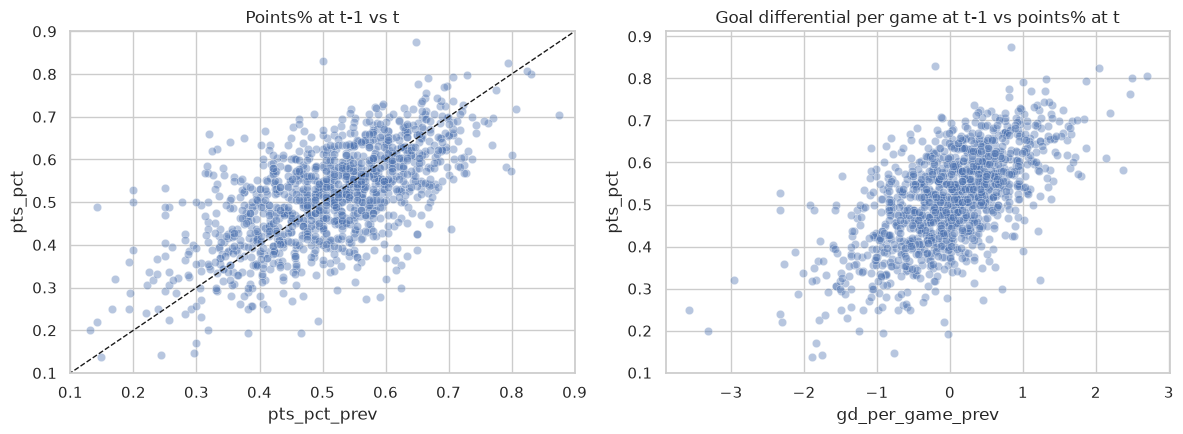

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=lag, x="pts_pct_prev", y="pts_pct", alpha=0.4, ax=ax[0])
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(title="Points% at t-1 vs t", xlim=(0.1, 0.9), ylim=(0.1, 0.9))
sns.scatterplot(data=lag, x="gd_per_game_prev", y="pts_pct", alpha=0.4, ax=ax[1])
ax[1].set(title="Goal differential per game at t-1 vs points% at t")
plt.tight_layout()

Does the year-to-year correlation hold in every era? Correlation per decade:

In [7]:
lag["decade"] = lag.year // 10 * 10
lag.groupby("decade").apply(
    lambda d: pd.Series({
        "n": len(d),
        "corr_pts_prev": d.pts_pct.corr(d.pts_pct_prev),
        "corr_gd_prev": d.pts_pct.corr(d.gd_per_game_prev),
    }), include_groups=False
).round(2)

,n,corr_pts_prev,corr_gd_prev
decade,,,
1910,6.0,0.13,0.28
1920,63.0,0.42,0.41
1930,82.0,0.54,0.58
1940,62.0,0.55,0.60
1950,60.0,0.69,0.71
1960,72.0,0.74,0.77
1970,160.0,0.79,0.80
1980,210.0,0.65,0.67
1990,245.0,0.58,0.58


## 4. Task (b): coach changes

Query in [`sql/coach_changes.sql`](../sql/coach_changes.sql). For each NHL team-season:

- `changed_between`: the coach who **started** season *t* is not the one who **ended** season *t-1* (the definition agreed with the professor);
- `changed_during`: more than one coach in season *t* (mid-season change).

In [8]:
cc = sql_file("coach_changes.sql")
cc_b = cc.dropna(subset=["changed_between"])
print(f"Change between seasons: {cc_b.changed_between.mean():.1%} of {len(cc_b)} team-seasons")
print(f"Change during season:   {cc.changed_during.mean():.1%} of {len(cc)} team-seasons")

Change between seasons: 26.0% of 1229 team-seasons
Change during season:   17.8% of 1265 team-seasons


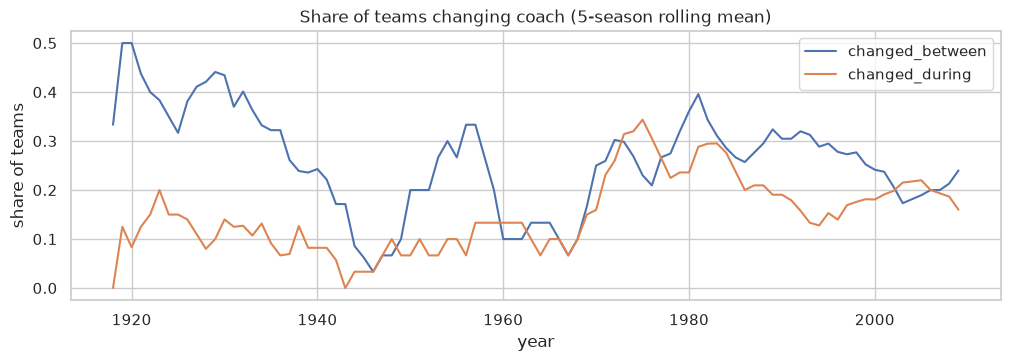

In [9]:
rate = cc_b.groupby("year")[["changed_between"]].mean().join(cc.groupby("year")[["changed_during"]].mean())
rate.rolling(5, min_periods=1).mean().plot(figsize=(12, 3.5), title="Share of teams changing coach (5-season rolling mean)")
plt.ylabel("share of teams");

Do teams that did badly last season change coach more often? Join with points% at *t-1*:

               mean  count
prev_quartile             
worst 25%      0.39    309
2nd            0.28    305
3rd            0.19    309
best 25%       0.18    305


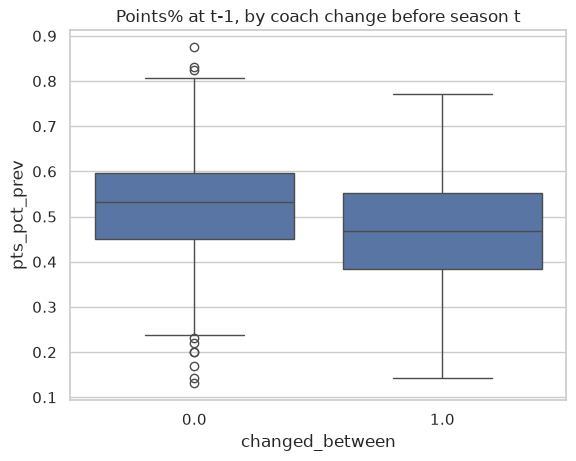

In [10]:
m = cc_b.merge(lag[["year", "franchID", "pts_pct_prev", "playoff"]], on=["year", "franchID"])
m["prev_quartile"] = pd.qcut(m.pts_pct_prev, 4, labels=["worst 25%", "2nd", "3rd", "best 25%"])
print(m.groupby("prev_quartile", observed=True).changed_between.agg(["mean", "count"]).round(2))

sns.boxplot(data=m, x="changed_between", y="pts_pct_prev")
plt.title("Points% at t-1, by coach change before season t");

## Findings so far

1. **Tables to drop.** `TeamsHalf` (1916–1920), the `*SC` tables (1912–1925), `ScoringSup` (1987–1990) and the shootout tables (2005–2009) cover too few seasons to help predict modern seasons.
2. **Last season predicts this season well.** The correlation between points% at *t-1* and *t* is about **0.63** overall. That is a strong baseline ("same as last season") that the models must beat.
3. **Goal differential is as good as points.** Goal differential per game at *t-1* correlates 0.64 with points% at *t*, about the same as points% at *t-1*. The two are highly redundant with each other (0.95).
4. **Predictability changes by era.** The year-to-year correlation peaks in the 1970s (0.79) and drops to about 0.57 in the 1990s–2000s (more teams, salary cap, more parity). This supports training mostly on recent seasons.
5. **Coach changes are common and imbalanced.** About **26%** of team-seasons start with a different coach from the one who ended the previous season, and about 18% change coach mid-season. Task (b) is an imbalanced classification problem (about 1 positive in 4).
6. **Bad teams change coach more.** In the worst 25% of teams by points% at *t-1*, 39% change coach, against 18% in the best 25%. Last season's performance will be a key feature for task (b).

### Data quality notes found so far

- Detroit 1998 has two coaches with `stint = 1` (co-coaches Dave Lewis and Barry Smith). Stints are not always unique per team-season.

In [11]:
con.close()